
<div style="text-align:center; padding:18px; border-radius:12px; background:#eef5ff;">
<h1 style="margin-bottom:4px;">Algoritmo de Metropolis en dos dimensiones</h1>
<h3 style="margin-top:0;">Simulación II · Python · Jupyter Notebook</h3>
</div>

### Objetivo

Implementar el algoritmo de **Metropolis** para generar una muestra aproximada de una distribución bidimensional y analizar su comportamiento mediante tres resultados gráficos:

- **Histograma de Metropolis** para las variables $x_1$ y $x_2$.
- **Gráfica 3D** de la función objetivo.
- **Gráfica de puntos** de la muestra, indicando la media y los principales estadísticos.



## 1. Formulación del problema

Se desea generar observaciones de una distribución bidimensional cuya función es:

$$
f(x_1,x_2)
=
C\exp\left[
-\frac{x_1^2x_2^2+x_1^2+x_2^2-8x_1-8x_2}{2}
\right]
$$

donde la constante es:

$$
C=\frac{1}{20216.335877}
$$

El problema consiste en obtener una muestra que siga el comportamiento de esta función. Como no se generarán directamente los pares $(x_1,x_2)$ mediante una distribución estándar de Python, se utiliza el **algoritmo de Metropolis**, un método de Monte Carlo basado en cadenas de Markov.

La idea es comenzar en un punto inicial y generar propuestas cercanas. Cada nueva propuesta se acepta o se rechaza de acuerdo con el valor de la función objetivo.



## 2. Método de Metropolis

Sea el estado actual de la cadena:

$$
X_t=(x_{1,t},x_{2,t})
$$

Se propone un nuevo punto:

$$
Y=X_t+Z,
\qquad Z\sim N(0,I)
$$

Después se calcula la probabilidad de aceptación:

$$
\alpha(X_t,Y)
=
\min\left(
1,\frac{f(Y)}{f(X_t)}
\right)
$$

También se genera un número aleatorio uniforme:

$$
U\sim U(0,1)
$$

La regla de decisión es:

$$
X_{t+1}=
\begin{cases}
Y, & \text{si } U<\alpha(X_t,Y),\\
X_t, & \text{si } U\geq\alpha(X_t,Y).
\end{cases}
$$

Así, los puntos con mayor valor de la función tienden a aceptarse con mayor frecuencia, aunque también se permiten algunos movimientos hacia regiones menos probables.



## 3. Implementación en Python

### Comentarios sobre la sintaxis

- `import` carga bibliotecas que contienen funciones ya programadas.
- `def` permite definir una función.
- `return` devuelve el resultado calculado por una función.
- `np.exp()` calcula la función exponencial.
- `np.random.normal()` genera números aleatorios con distribución normal.
- `np.random.uniform()` genera un número aleatorio entre 0 y 1.
- `for` repite una serie de instrucciones.
- `if` y `else` permiten tomar decisiones.
- `muestras[t]` accede a una posición específica de un arreglo.
- `muestras[burn_in:]` toma todas las observaciones desde `burn_in` hasta el final.


In [1]:

# Se configura una carpeta temporal para Matplotlib antes de importarlo.
# Esto evita mensajes de configuración ajenos al algoritmo.
import os
os.environ["MPLCONFIGDIR"] = "./mplconfig"

import numpy as np
import matplotlib.pyplot as plt

# Semilla para reproducir los mismos resultados.
np.random.seed(2026)

# Constante de normalización dada en clase.
C = 1 / 20216.335877

# 'def' define la función objetivo.
def f(x1, x2):
    exponente = -(x1**2 * x2**2 + x1**2 + x2**2 - 8*x1 - 8*x2) / 2
    return C * np.exp(exponente)

# Calcula la probabilidad de aceptación de Metropolis.
def calcular_alpha(x_actual, propuesta):
    f_actual = f(x_actual[0], x_actual[1])
    f_propuesta = f(propuesta[0], propuesta[1])

    if f_actual == 0:
        return 1.0

    return min(1.0, f_propuesta / f_actual)

# Algoritmo de Metropolis.
def metropolis(N, x1_inicial=0.0, x2_inicial=0.0):
    # np.zeros crea un arreglo de N filas y 2 columnas.
    muestras = np.zeros((N, 2))
    muestras[0] = [x1_inicial, x2_inicial]

    aceptadas = 0

    # Repetimos el procedimiento N-1 veces.
    for t in range(N - 1):
        x_actual = muestras[t]

        # Propuesta aleatoria Y = X_t + Z, con Z ~ N(0,I).
        z = np.random.normal(0, 1, size=2)
        propuesta = x_actual + z

        # Probabilidad de aceptación.
        alpha = calcular_alpha(x_actual, propuesta)

        # Número uniforme entre 0 y 1.
        u = np.random.uniform(0, 1)

        # Se acepta o rechaza la propuesta.
        if u < alpha:
            muestras[t + 1] = propuesta
            aceptadas += 1
        else:
            muestras[t + 1] = x_actual

    tasa_aceptacion = aceptadas / (N - 1)

    return muestras, tasa_aceptacion



## 4. Ejecución de la simulación

Se generan $30\,000$ estados de la cadena. Para reducir la influencia del punto inicial se eliminan las primeras $5\,000$ observaciones como **burn-in**.

Después se calculan las medias:

$$
\bar{x}_1=\frac{1}{n}\sum_{i=1}^{n}x_{1,i},
\qquad
\bar{x}_2=\frac{1}{n}\sum_{i=1}^{n}x_{2,i}
$$

También se obtienen la desviación estándar, la matriz de covarianza y la tasa de aceptación.


In [2]:

N = 30000
burn_in = 5000

# Ejecutamos el algoritmo.
cadena, tasa_aceptacion = metropolis(N)

# Eliminamos el periodo de burn-in.
muestras = cadena[burn_in:]

# Estadísticos principales.
media = muestras.mean(axis=0)
desv = muestras.std(axis=0, ddof=1)
covarianza = np.cov(muestras.T)

print(f"Muestras utilizadas: {len(muestras)}")
print(f"Tasa de aceptación: {100*tasa_aceptacion:.2f}%")
print(f"Media muestral: ({media[0]:.4f}, {media[1]:.4f})")
print(f"Desviación estándar: ({desv[0]:.4f}, {desv[1]:.4f})")
print("Matriz de covarianza:")
print(covarianza)


Muestras utilizadas: 25000
Tasa de aceptación: 30.86%
Media muestral: (1.9349, 1.7876)
Desviación estándar: (1.6870, 1.6300)
Matriz de covarianza:
[[ 2.84611344 -2.30469328]
 [-2.30469328  2.65682411]]



## 5. Histograma de Metropolis

Un histograma representa la frecuencia de los datos mediante **barras**. Como la simulación produce dos variables, $x_1$ y $x_2$, ambas se muestran en el mismo gráfico para comparar sus distribuciones.


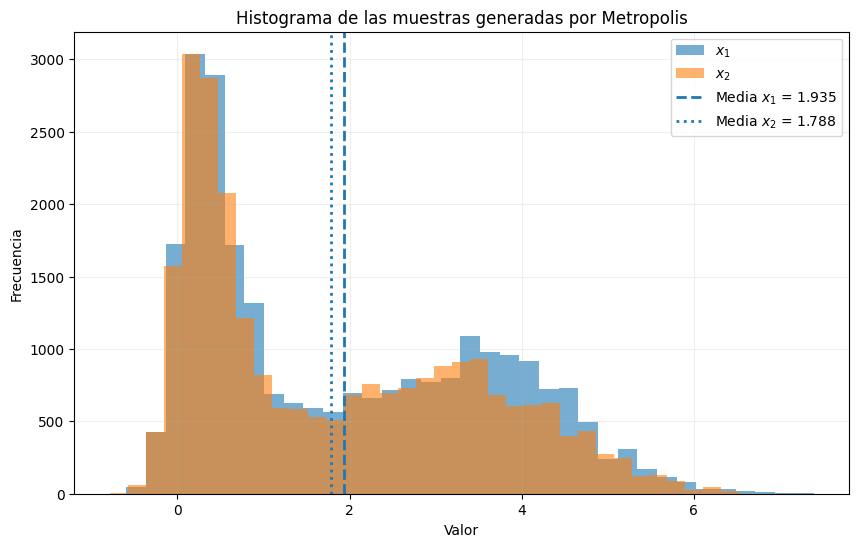

In [3]:

plt.figure(figsize=(10, 6))

# plt.hist construye histogramas de barras.
# bins=35 indica el número de intervalos utilizados.
plt.hist(muestras[:, 0], bins=35, alpha=0.60, label=r'$x_1$')
plt.hist(muestras[:, 1], bins=35, alpha=0.60, label=r'$x_2$')

# Se señalan las medias de cada variable.
plt.axvline(media[0], linestyle='--', linewidth=2, label=fr'Media $x_1$ = {media[0]:.3f}')
plt.axvline(media[1], linestyle=':', linewidth=2, label=fr'Media $x_2$ = {media[1]:.3f}')

plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.title('Histograma de las muestras generadas por Metropolis')
plt.legend()
plt.grid(alpha=0.20)
plt.show()



## 6. Gráfica 3D de la función

La superficie 3D permite observar la forma de la función objetivo. Las zonas de mayor altura corresponden a valores mayores de $f(x_1,x_2)$ y son regiones que la cadena de Metropolis debe visitar con mayor frecuencia.


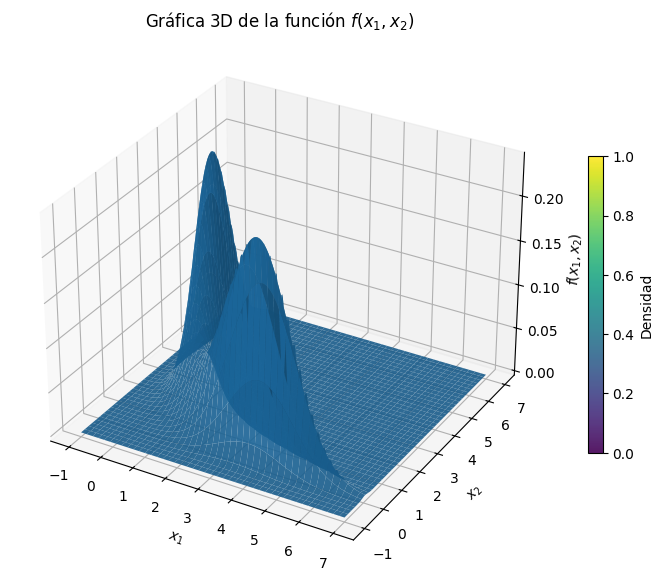

In [4]:

# Valores utilizados para construir la malla.
x1 = np.linspace(-1, 7, 220)
x2 = np.linspace(-1, 7, 220)

# np.meshgrid forma todas las combinaciones de x1 y x2.
X1, X2 = np.meshgrid(x1, x2)

# Evaluamos la función en cada punto de la malla.
Z = f(X1, X2)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# plot_surface dibuja la superficie tridimensional.
superficie = ax.plot_surface(X1, X2, Z, edgecolor='none', alpha=0.90)

ax.set_xlabel(r'$x_1$')
ax.set_ylabel(r'$x_2$')
ax.set_zlabel(r'$f(x_1,x_2)$')
ax.set_title(r'Gráfica 3D de la función $f(x_1,x_2)$')

fig.colorbar(superficie, ax=ax, shrink=0.55, label='Densidad')
plt.show()



## 7. Gráfica de puntos, media y estadísticos

La nube de puntos muestra los pares $(x_1,x_2)$ generados por Metropolis. El símbolo **X** representa la media muestral:

$$
(\bar{x}_1,\bar{x}_2)
$$

También se muestran la desviación estándar y la tasa de aceptación obtenidas en la simulación.


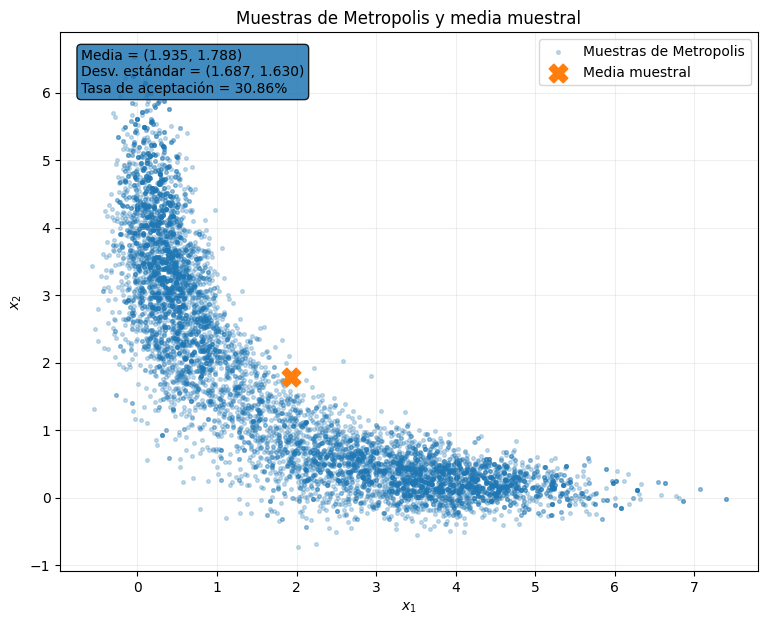

In [5]:

plt.figure(figsize=(9, 7))

# Se grafica uno de cada tres puntos para que la figura sea más clara.
plt.scatter(
    muestras[::3, 0],
    muestras[::3, 1],
    s=7,
    alpha=0.25,
    label='Muestras de Metropolis'
)

# Se marca la media muestral.
plt.scatter(
    media[0],
    media[1],
    s=180,
    marker='X',
    label='Media muestral'
)

# Información numérica dentro de la gráfica.
texto = (
    f"Media = ({media[0]:.3f}, {media[1]:.3f})\n"
    f"Desv. estándar = ({desv[0]:.3f}, {desv[1]:.3f})\n"
    f"Tasa de aceptación = {100*tasa_aceptacion:.2f}%"
)

plt.text(
    0.03, 0.97, texto,
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', alpha=0.85)
)

plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.title('Muestras de Metropolis y media muestral')
plt.legend()
plt.grid(alpha=0.20)
plt.show()



## 8. Resultado final

<div style="padding:14px; border-left:6px solid #2e7d32; background:#eef8ef; border-radius:8px;">

**Conclusión.** El algoritmo de Metropolis permitió generar una muestra de la distribución bidimensional propuesta.

El **histograma de barras** permite observar la distribución de $x_1$ y $x_2$; la **gráfica 3D** muestra la forma de la función objetivo; y la **gráfica de puntos** permite observar los pares generados y localizar su media muestral.

La media, la desviación estándar, la covarianza y la tasa de aceptación complementan el análisis numérico de la simulación.

</div>
